# Seven-qubit processor (A. Dahima): a Quantcore-PDK rebuild, step by step

**Source:** Atharve Dahima, *7-qubit-superconducting-processor*, `simon_7qubit_complete_chip.py` (the routed
end-of-lecture chip) and its exported mask `seven_qubit_chip_mask.gds`,
<https://github.com/atharveeee-netizen/7-qubit-superconducting-processor>. The README badge says MIT but the repo has no
LICENSE file; it is rebuilt regardless (decision, 2026-11-03), credited here and distributed under the GPL. A depth-1 clone was
read on 2026-11-03 in `build/external/7-qubit-superconducting-processor` (read only, never executed); the mask is in
`build/external/7q/`. Spec: `docs/designs/community/seven_qubit_processor.md`.

**What the chip is:** 7 pocket transmons in a U chain Q0–Q1–Q3–Q4–Q5–Q2–Q6 on a 10 × 10 mm chip.
- Six are `TransmonPocket6`; Q4 is a `TransmonPocketCL` with a charge line.
- Six meandered buses join neighbours (Metal `RouteMeander`, default 7 mm).
- Six meanders run from the qubits' readout pads straight to wirebond pads (no resonators, no feedline).
- The exported mask carries Quantum Metal's default GDS cheese: 25 µm square holes on a 100 µm pitch over the whole
  ground, 25 µm clear of all geometry (`no_cheese` buffer), with a ≈ 190 µm band clear along the chip edge.

README targets: f_q 4.8–5.2 GHz, α −280…−330 MHz, f_r 6.8–7.4 GHz in 100 MHz steps, g 50–70 MHz. The source's own
Q3D/LOM run on Q4 gives C_Σ 74.70 fF, L_J 12.305 nH and f_q 4.974 GHz.

**This notebook rebuilds the chip in the Quantcore PDK; it is not a replica.** What the rebuild keeps and what the PDK
changes:

| topic | source | this rebuild |
|---|---|---|
| die and frame | 10 × 10 mm Metal chip centred on (0, 0), no frame | PDK frame on the same die (Designer = source + (5000, 5000) µm, then centred), device ID `SQP-7Q` |
| stack | silicon (README) | PDK sapphire 650 µm, εr 10.25 |
| qubits | Metal `TransmonPocket6` / `TransmonPocketCL` (pads 455 × 90 µm, gap 30, pocket 650 × 650) | the same cells and options through the `metal:` wrappers, same positions and orientations |
| junctions | lumped L_J 10–12.3 nH | Quantcore trilayer junctions sized for a staggered 4.80–5.20 GHz plan (`size_junction`); R_n is flagged, not retuned |
| readout | a meander galvanically joined to a pad per qubit | a λ/4 hanger per qubit on one ∩ feedline round the chain, 6.8–7.3 GHz |
| buses | six 7 mm `RouteMeander`s | the same lengths: two drawn serpentines (outer) and four qcc meanders |
| pads | six readout wirebond pads | three `LaunchpadWirebond`s (feed in, feed out, Q4's charge line), **`frame.pad_edge` = 100 µm from the die edge** (PDK pad rule) |
| placement | the chain sits above the chip centre | **PDK**: the chip core (qubits, buses, readouts, feedline) is centred in the die |
| cheese | Metal's GDS cheese in the exported mask | **the original's cheese**: Metal's rule drawn by the build (`cheese` = `metal_cheese_rule()`) and kept in the mask; no PDK band |

## 1 · Setup and the PDK

The notebook runs from the repository root. `_common` holds the table, snapshot and PDK helpers shared by the design
notebooks. `LIVE` follows `QCC_LIVE`: with KLayout open, every change below shows up live; with `QCC_LIVE=0` (tests,
batch runs) the snapshots are rendered headless.

`sizing_md` tabulates the junction sizing; `center_core` centres the chip's core, leaving out the pads (pinned to the
die edge) and the charge-line lead that runs to one of them.

In [1]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.circuit.bridges import size_junction, tl_resonator
from quantcore_circuits.layouts.registry import trilayer_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/community")
OUT.mkdir(parents=True, exist_ok=True)


def sizing_md(sizing):
    """Trilayer junction sizing (``circuit.bridges.size_junction``) against the PDK junction rule."""
    rows = ["| qubit | f_q target (GHz) | C_Σ (fF) | L_J (nH) | R_n (kΩ) | drawn f_q (GHz) | R_n in 40–50 kΩ |",
            "|---|---|---|---|---|---|---|"]
    for name, s in sizing.items():
        rows.append(f"| {name} | {s.f_q_GHz:.3f} | {s.c_sigma_fF:.1f} | {s.lj_nH:.2f} | {s.rn_kohm:.1f} | "
                    f"{s.f_q_drawn_GHz:.3f} | {'yes' if s.rn_in_window else 'no'} |")
    return "\n".join(rows)


def center_core(d, skip=(), tol=50.0):
    """Centre the chip's core (every instance and route except ``skip``) in the die: shift the whole design so the
    core's bounding box is centred (pads pinned to an edge keep their edge distance). Returns the shift (µm)."""
    from kqcircuits.pya_resolver import pya
    from quantcore_circuits.assembly.sidecar import sidecar_dict

    side = sidecar_dict(rebuild(d), overlays=False)
    box = pya.DBox()
    for name, inst in side["instances"].items():
        if name not in skip and inst.get("bbox"):
            box += pya.DBox(*inst["bbox"])
    for name, route in side["routes"].items():
        if name not in skip:
            for x, y in route.get("polyline") or []:
                box += pya.DPoint(x, y)
    x0, y0, x1, y1 = d.design.chip.box
    dx, dy = round((x0 + x1) / 2 - box.center().x, 1), round((y0 + y1) / 2 - box.center().y, 1)
    if abs(dx) <= tol and abs(dy) <= tol:
        return (0.0, 0.0)
    translate_design(d, dx, dy)
    return (dx, dy)

The PDK facts this chip relies on. Every rule is applied by the library, not by this notebook: the frame and the cheese by
the chip build, the pad rule by `edge=`, the junctions by `trilayer_junction`, the design warnings by the DRC.

In [2]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 2 · The die and the frame

`Designer(name, box=...)` opens an empty chip. The source's 10 × 10 mm chip is kept, so Designer = source +
(5000, 5000) µm (until the centring in step 6). The PDK draws the frame round it: L dicing markers (1000/0), 3 × 3
alignment grids (1001/0), the chip boundary (100/0) and the device ID (`name_chip`) on a free edge.

**Cheese: the original's.** The source's exported mask `seven_qubit_chip_mask.gds` carries Quantum Metal's default GDS
cheese (its `QGDSRenderer` defaults: 25 µm squares every 100 µm, 25 µm clear of all geometry, none near the chip
edge). The original wins over the PDK band: `chip={"cheese": metal_cheese_rule()}` hands the build Metal's rule
(25 µm squares every 100 µm, 25 µm clear of the 3/0 keep-outs, none within 200 µm of the die edge), and the build
draws it instead of the band.

chip cheese rule: {'size': 25.0, 'gap': 75.0, 'rows': 1000, 'clearance': 25.0, 'edge': 200.0}


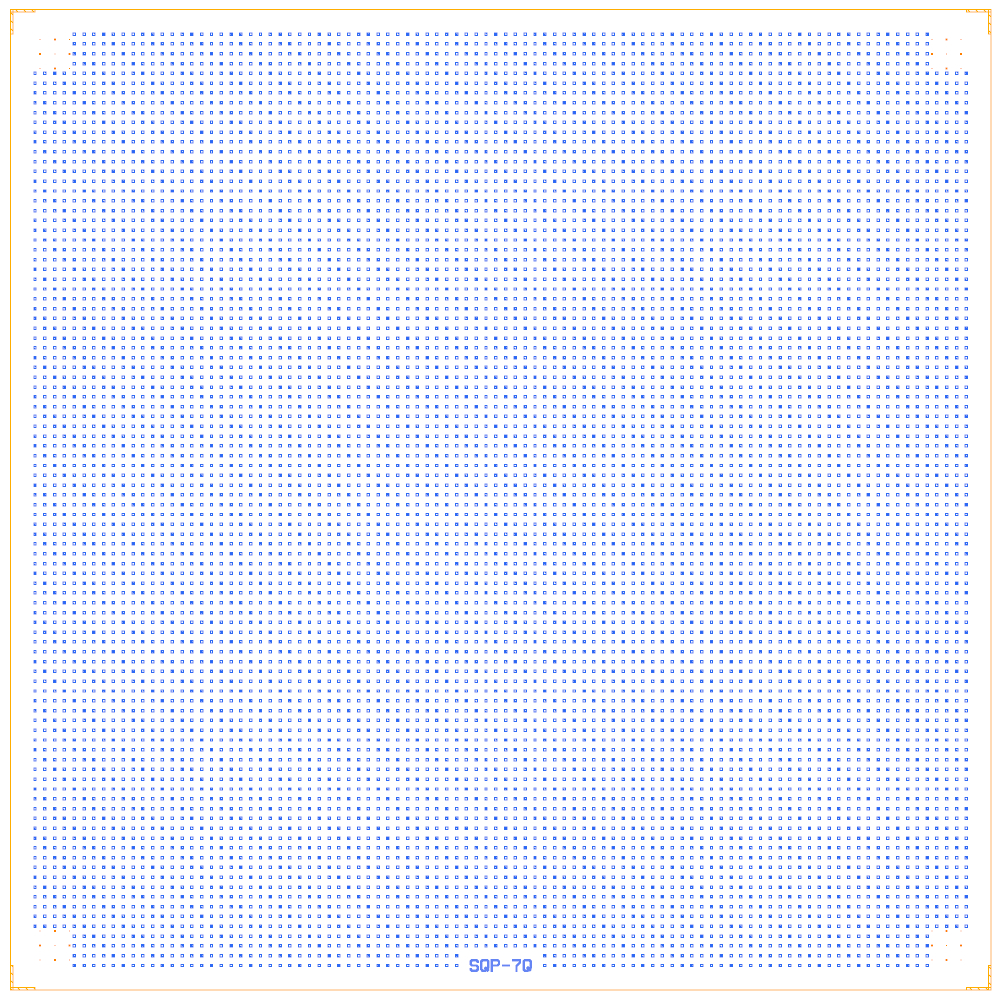

In [3]:
X0 = Y0 = 5000.0                                   # the source's 10 × 10 mm chip is centred on (0, 0)
d = Designer("seven_qubit_processor", box=(0, 0, 10000, 10000), chip={"name_chip": "SQP-7Q", "cheese": metal_cheese_rule()},
             live=LIVE)
print("chip cheese rule:", d.design.chip.params["cheese"])
snap(d, OUT / "seven_qubit_processor_die.png", size=(1000, 1000), width=360);

## 3 · Pads: three launchpads and the PDK pad rule

The source has six readout wirebond pads; the rebuild replaces its galvanic readouts by a feedline (step 5), so it needs
three `metal:LaunchpadWirebond`s:
- **LP_IN / LP_OUT**, the feedline's input and output, on the west and east edges at the height where the feedline legs
  end (`PAD_Y`), facing in;
- **LP_CL**, Q4's charge line, on the south edge below Q4, facing north.

The PDK puts every bond pad with the outer edge of its etch **`frame.pad_edge` = 100 µm from the die edge**:
`edge="w"` / `"e"` / `"s"` slides a pad perpendicular to that edge until it holds and keeps its position along the edge.

In [4]:
FL_X, FL_TOP, PAD_Y = 1000.0, 8700.0, 2300.0       # ∩ feedline: legs at x = 1000 / 9000, top at y = 8700, feet at 2300
with d.batch():
    lp_in = d.add("LP_IN", "metal:LaunchpadWirebond", at=(FL_X, PAD_Y), rot=0, edge="w")
    lp_out = d.add("LP_OUT", "metal:LaunchpadWirebond", at=(10000 - FL_X, PAD_Y), rot=180, edge="e")
    lp_cl = d.add("LP_CL", "metal:LaunchpadWirebond", at=(X0 - 5, PAD_Y), rot=90, edge="s")
rebuild(d)
display(Markdown(pads_md(d)))

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| LP_IN | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LP_OUT | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |
| LP_CL | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |

## 4 · Components: seven pocket transmons with trilayer junctions

**Junction sizing.** The source gives no per-qubit L_J, only the README window. The rebuild staggers the qubits over
4.80–5.20 GHz and sizes each Quantcore trilayer junction with `circuit.bridges.size_junction(f_q, C_Σ)` on the LOM C_Σ
of the pocket (63.5 fF; the source's Q3D gives 74.7 fF). `trilayer_junction(cell, lj_nH=...)` turns the L_J into the
cell parameters that draw the junction (fingers on 2/0 and 4/0, spacer 50/0 with the 51–53/0 gradient) and the values
the LOM uses.

At this C_Σ a 4.8–5.2 GHz qubit needs E_J/h ≈ 12–14 GHz, so R_n comes out 86–102 kΩ, **outside the PDK window of
40–50 kΩ** (the table says which). Inside the window the qubits would sit at ≈ 6.5–7 GHz, next to the readouts.
Following the project rule (values are flagged, never retuned), the plan stays and the DRC reports `pdk_rn`.

In [5]:
C_SIGMA = 63.5      # fF: LOM C_Σ of the pocket in its readout group (source Q3D of Q4: 74.70 fF); sizes every junction
F_Q = dict(Q0=4.80, Q1=5.10, Q3=4.85, Q4=5.15, Q5=4.90, Q2=5.20, Q6=4.95)   # README window 4.8–5.2 GHz, staggered
SIZING = {q: size_junction(f, C_SIGMA) for q, f in F_Q.items()}
display(Markdown(sizing_md(SIZING)))

| qubit | f_q target (GHz) | C_Σ (fF) | L_J (nH) | R_n (kΩ) | drawn f_q (GHz) | R_n in 40–50 kΩ |
|---|---|---|---|---|---|---|
| Q0 | 4.800 | 63.5 | 15.31 | 102.3 | 4.800 | no |
| Q1 | 5.100 | 63.5 | 13.65 | 91.2 | 5.137 | no |
| Q3 | 4.850 | 63.5 | 15.01 | 100.3 | 4.800 | no |
| Q4 | 5.150 | 63.5 | 13.41 | 89.6 | 5.137 | no |
| Q5 | 4.900 | 63.5 | 14.72 | 98.4 | 4.915 | no |
| Q2 | 5.200 | 63.5 | 13.16 | 88.0 | 5.245 | no |
| Q6 | 4.950 | 63.5 | 14.44 | 96.5 | 4.915 | no |

**The qubits.** The source's pockets (pads 455 × 90 µm, gap 30 µm, pocket 650 × 650 µm) at the source positions and
orientations. The connection-pad corners (`loc_W`, `loc_H`) are chosen so each bus pad faces its neighbour (the
source's corners send Q0–Q1 and Q2–Q6 round the pockets). Q4 is a `TransmonPocketCL`: two 50 × 30 µm bus pads and a
charge line (`Charge_Line` pin).

<metal:TransmonPocketCL Q4 ports=['Charge_Line', 'bus_left', 'bus_right', 'squid_a', 'squid_b']>


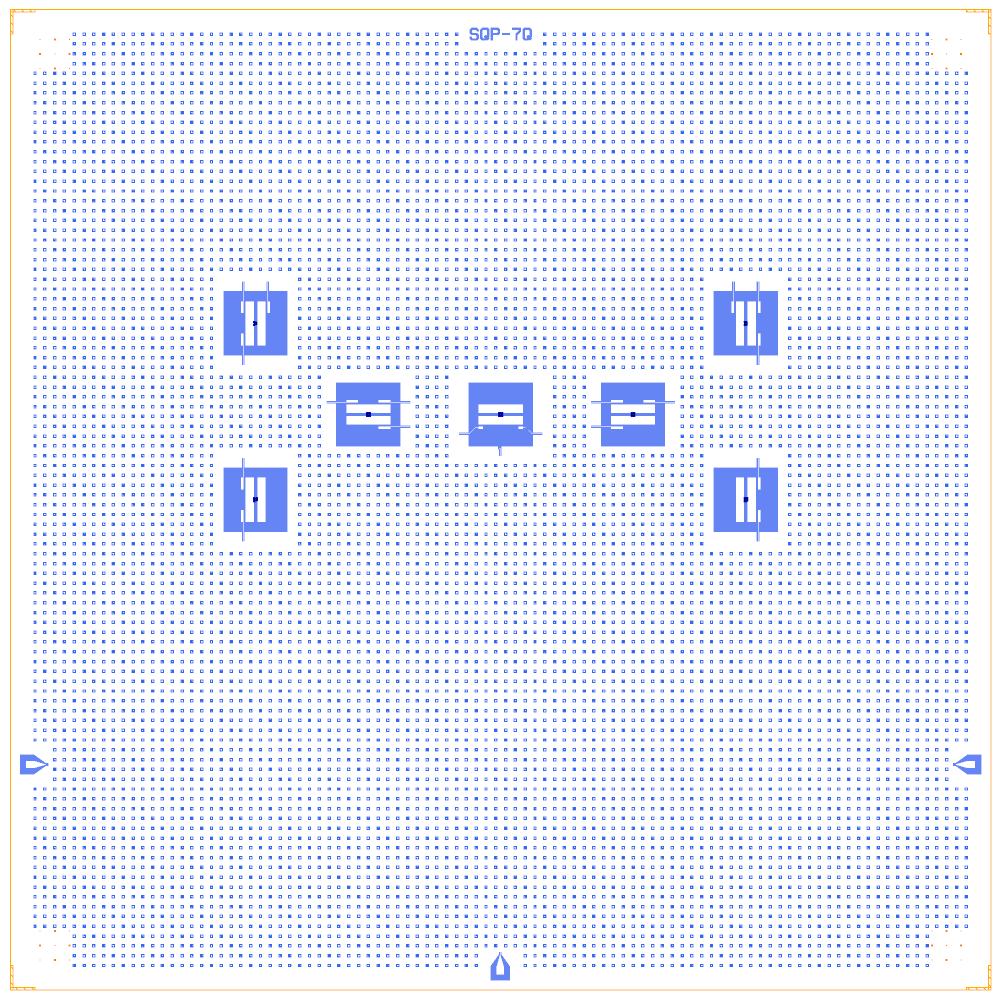

In [6]:
POCKET = dict(pad_width=455, pad_height=90, pad_gap=30, pocket_width=650, pocket_height=650)
UP, DN = 1, -1                                     # rot 90 (Q0, Q1, Q2, Q6): loc_W = +1 top, −1 bottom
L_, R_ = 1, -1                                     #                         loc_H = +1 left, −1 right
QUBITS = {  # name: ((x, y) source µm, rot, connection_pads)
    "Q0": ((-2500, 0), 90, dict(bus_top=dict(loc_W=UP, loc_H=L_), readout=dict(loc_W=DN, loc_H=L_))),
    "Q1": ((-2500, 1800), 90, dict(bus_bot=dict(loc_W=DN, loc_H=L_), bus_right=dict(loc_W=UP, loc_H=R_),
                                    readout=dict(loc_W=UP, loc_H=L_))),
    "Q3": ((-1350, 870), 0, dict(bus_left=dict(loc_W=-1, loc_H=1), bus_right=dict(loc_W=1, loc_H=-1),
                                  readout=dict(loc_W=1, loc_H=1))),
    "Q5": ((1350, 870), 0, dict(bus_left=dict(loc_W=-1, loc_H=-1), bus_right=dict(loc_W=1, loc_H=1),
                                 readout=dict(loc_W=-1, loc_H=1))),
    "Q2": ((2500, 1800), 90, dict(bus_bot=dict(loc_W=DN, loc_H=R_), bus_left=dict(loc_W=UP, loc_H=L_),
                                   readout=dict(loc_W=UP, loc_H=R_))),
    "Q6": ((2500, 0), 90, dict(bus_top=dict(loc_W=UP, loc_H=R_), readout=dict(loc_W=DN, loc_H=R_))),
}
CL = dict(make_CL=True, cl_gap=6, cl_width=10, cl_length=20, cl_ground_gap=6, cl_pocket_edge="50", cl_off_center=0)
Q4_PADS = dict(bus_left=dict(loc_W=-1, loc_H=-1, pad_width=50, pad_height=30),
               bus_right=dict(loc_W=1, loc_H=-1, pad_width=50, pad_height=30))
q = {}
with d.batch():
    for name, ((x, y), rot, pads) in QUBITS.items():
        params, jj = trilayer_junction("metal:TransmonPocket6", lj_nH=SIZING[name].lj_nH)
        q[name] = d.add(name, "metal:TransmonPocket6", at=(X0 + x, Y0 + y), rot=rot, junction=jj,
                        connection_pads=pads, **POCKET, **params)
    params, jj = trilayer_junction("metal:TransmonPocketCL", lj_nH=SIZING["Q4"].lj_nH)
    q["Q4"] = d.add("Q4", "metal:TransmonPocketCL", at=(X0, Y0 + 870), junction=jj, connection_pads=Q4_PADS,
                    **POCKET, **CL, **params)
print(q["Q4"])
snap(d, OUT / "seven_qubit_processor_components.png", size=(1000, 1000), width=360);

## 5 · Routes: the feedline, six λ/4 hangers, six buses and the charge line

**The feedline** runs from LP_IN's `tie` east to the left leg, up, across the top and down the right leg to LP_OUT: a ∩
round the chain, so every readout hangs on its inner side.

In [7]:
fl = d.route("FL", lp_in.tie, lp_out.tie,
             nodes=[(FL_X, PAD_Y), (FL_X, FL_TOP), (10000 - FL_X, FL_TOP), (10000 - FL_X, PAD_Y)])
rebuild(d)
print(f"FL: {fl.length:.1f} µm")

FL: 21858.3 µm


**Readouts.** Each readout is a λ/4 route from the qubit's readout pad: meander → a 250 µm section along the feedline
with a 6 µm ground strip → short to ground, at the README's 6.8–7.3 GHz.
- `fl.hanger(near=(x, y), length=250, side="right", ...)` centres the coupled section at the feedline point nearest
  (x, y): on the left leg for Q0/Q1, on the top for Q3/Q5, on the right leg for Q2/Q6. Placing it by position, not by
  arclength from LP_IN, keeps it in place when the pads or the feedline's ends move. `direction` sets which end of the
  coupled section is shorted.
- The lengths are the PDK CPW's v_ph / 4f, minus 6.7 % for the C_g and hanger pull seen in the LOM (`tl_resonator`
  gives v_ph of the 10/6 µm CPW on sapphire).

In [8]:
F_R = dict(Q0=6.8, Q1=6.9, Q3=7.0, Q5=7.1, Q2=7.2, Q6=7.3)                   # README 6.8–7.4 GHz, 100 MHz steps
VP = tl_resonator(4500, 10, 6)["vp_m_s"]           # PDK stack (sapphire): phase velocity of the 10/6 µm CPW
L_RO = {k: round(VP / (4 * f * 1e9) * 1e6 * 0.933, 1) for k, f in F_R.items()}  # λ/4, −6.7 %: C_g + hanger pull (LOM)
HG = dict(length=250, side="right", ground_gap=6, end="short")
NEAR = {"Q0": ((FL_X, 3300), "forward"), "Q1": ((FL_X, 7600), "backward"), "Q3": ((3900, FL_TOP), "forward"),
        "Q5": ((6100, FL_TOP), "backward"), "Q2": ((10000 - FL_X, 7600), "forward"),
        "Q6": ((10000 - FL_X, 3300), "backward")}
VIA = {"Q3": [(4300, 5995), (4300, 8000), (3775, 8000)], "Q5": [(5700, 5995), (5700, 8000), (6225, 8000)]}
with d.batch():
    for n, (at, direction) in NEAR.items():
        d.route(f"R_{n}", q[n].readout, fl.hanger(near=at, direction=direction, **HG), meander=L_RO[n], r=50,
                nodes=VIA.get(n))
print(L_RO)

{'Q0': 4323.2, 'Q1': 4260.5, 'Q3': 4199.7, 'Q5': 4140.5, 'Q2': 4083.0, 'Q6': 4027.1}


**Buses.** The source's buses are 7 mm `RouteMeander`s (Metal's default length; the source sets none), λ/2 resonators
between two bus pads.
- The two outer buses (Q0–Q1, Q2–Q6) are drawn serpentines (`nodes=SERP`, 40 µm bends) whose drawn path is 6994 µm:
  the router's own meander in that 950 µm gap crosses itself, so the path is given and the length pinned to it.
- The four inner buses are qcc meanders of 7000 µm on waypoints.

**Charge line.** Q4's charge line is drawn but unrouted in the source; here it runs straight down to LP_CL.

{'FL': 21858.3, 'R_Q0': 4323.2, 'R_Q1': 4260.5, 'R_Q3': 4199.7, 'R_Q5': 4140.5, 'R_Q2': 4083.0, 'R_Q6': 4027.1, 'Bus_Q0_Q1': 6994.0, 'Bus_Q1_Q3': 7000.0, 'Bus_Q3_Q4': 7000.0, 'Bus_Q4_Q5': 7000.0, 'Bus_Q5_Q2': 7000.0, 'Bus_Q2_Q6': 6994.0, 'CL_Q4': 5068.0}


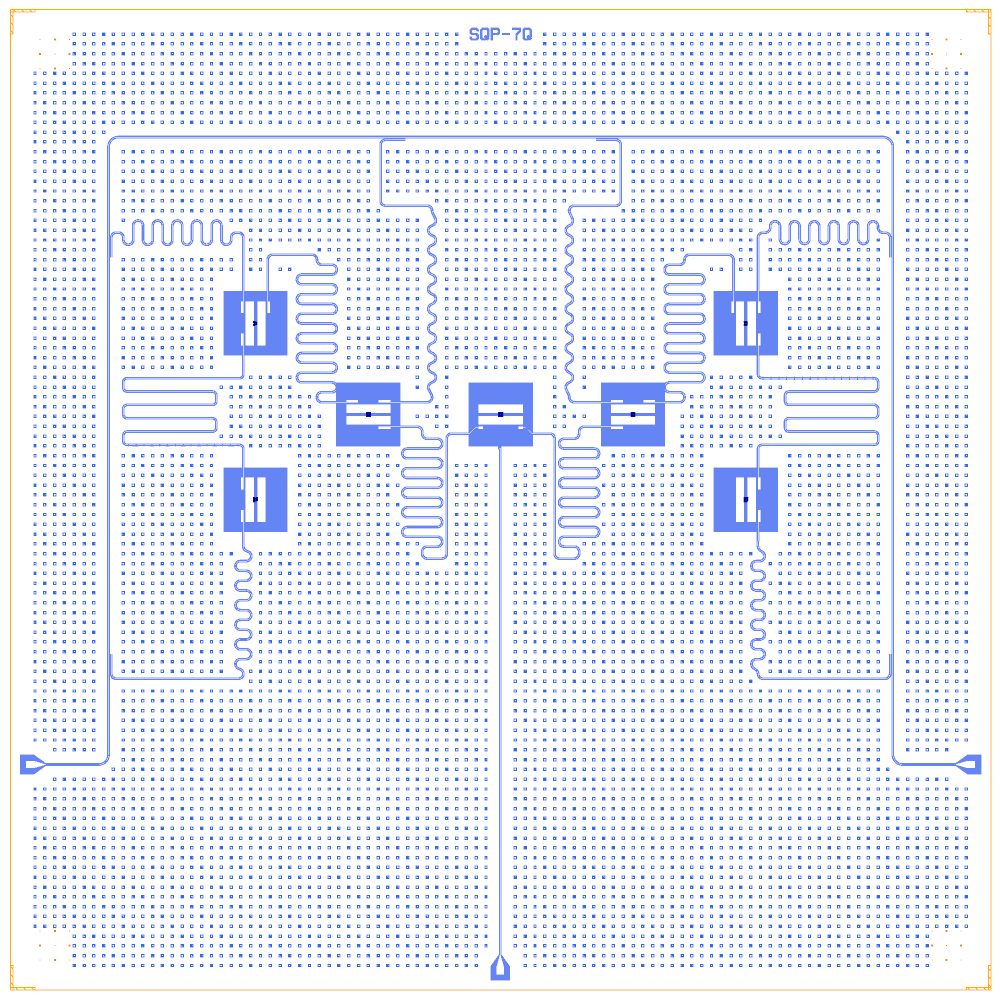

In [9]:
SERP = [(2375, 5560), (1150, 5560), (1150, 5696), (2100, 5696), (2100, 5832), (1150, 5832), (1150, 5968),
        (2100, 5968), (2100, 6104), (1150, 6104), (1150, 6240), (2375, 6240)]
L_SERP = 6994.03                                   # drawn path 6993.98 µm + 0.05
with d.batch():
    d.route("Bus_Q0_Q1", q["Q0"].bus_top, q["Q1"].bus_bot, meander=L_SERP, r=40, nodes=SERP)
    d.route("Bus_Q1_Q3", q["Q1"].bus_right, q["Q3"].bus_left, meander=7000, r=50,
            nodes=[(2625, 7500), (3125, 7500), (3125, 5995)])
    d.route("Bus_Q3_Q4", q["Q3"].bus_right, q["Q4"].bus_left, meander=7000, r=50,
            nodes=[(4200, 5745), (4200, 4400), (4450, 4400), (4450, 5675)])
    d.route("Bus_Q4_Q5", q["Q4"].bus_right, q["Q5"].bus_left, meander=7000, r=50,
            nodes=[(5550, 5675), (5550, 4400), (5800, 4400), (5800, 5745)])
    d.route("Bus_Q5_Q2", q["Q5"].bus_right, q["Q2"].bus_left, meander=7000, r=50,
            nodes=[(6875, 5995), (6875, 7500), (7375, 7500)])
    d.route("Bus_Q2_Q6", q["Q2"].bus_bot, q["Q6"].bus_top, meander=L_SERP, r=40,
            nodes=[(10000 - x, y) for x, y in reversed(SERP)])
    d.route("CL_Q4", lp_cl.tie, q["Q4"].Charge_Line)
    for n in F_R:
        d.sim_group(f"{n}R", [n, f"R_{n}", "FL"])
    d.sim_group("Q3Q4Q5", ["Q3", "Q4", "Q5", "Bus_Q3_Q4", "Bus_Q4_Q5"], analyses=["q3d_cmatrix"])
    d.targets(**{n: {"f_q_GHz": f} for n, f in F_Q.items()}, **{f"R_{n}": {"f_GHz": f} for n, f in F_R.items()})
rebuild(d)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})
snap(d, OUT / "seven_qubit_processor_routes.png", size=(1000, 1000), width=360);

## 6 · PDK placement: centre the core

The PDK wants the chip content in the middle of the die. Here the qubit chain sits above the centre (as in the source)
and the feedline wraps it, so the core (qubits, buses, readouts and the feedline) is ≈ 0.5 mm high. `center_core`
measures the core's bounding box (leaving out the three launchpads, which are pinned to the die edge, and the charge-line
lead running to one of them) and shifts the whole design: instance positions, route waypoints and hanger `near` points.
The pads move along their edge with it and keep their 100 µm from it. This run: shift (0, −500) µm.

In [10]:
shift = center_core(d, skip=("LP_IN", "LP_OUT", "LP_CL", "CL_Q4"))
print("shift applied (µm):", shift)
rebuild(d)
display(Markdown(pads_md(d)))

shift applied (µm): (0.0, -500.0)


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| LP_IN | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LP_OUT | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |
| LP_CL | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |

## 7 · DRC

`d.drc()` checks connectivity (dangling ports, overlaps, route crossings, netlist opens and shorts) and the PDK margins:
- **errors** would make the chip wrong; there must be none;
- **warnings** are worth a look but can be intended: here the 14 junction attachment points (`squid_a` / `squid_b`;
  the cell draws its own junction), not route ends;
- **PDK design warnings** flag values outside the PDK margins (`pdk_rn`, `pdk_fq`, `pad_edge`, `pdk_claw`); they are
  reported, never enforced. Here: `pdk_rn` on the seven junctions (the 4.8–5.2 GHz plan).

Expected (this run): **no errors**; 14 `dangling_port` warnings (`squid_a` / `squid_b`); 7 `pdk_rn` (86.5–102.3 kΩ as
drawn). No `pad_edge`: the three launchpads sit at 100 µm.

`pdk_report(d)` sums up the PDK checks. Its content centre (0, −850 µm) includes the edge pads and Q4's charge-line
lead, which `center_core` leaves out: the core itself is centred.

In [11]:
rebuild(d)
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 14 warnings · 7 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 14 | Q0.squid_a is not connected (no route or snap) |
| PDK design warning | `pdk_rn` | 7 | Q0: junction R_n 102.3 kΩ is outside the PDK window 40–50 kΩ (L_J 15.3055 nH) |

| check | value |
|---|---|
| cheese | the original design's rule (drawn in the build): size 25, gap 75, rows 1000, clearance 25, edge 200 |
| content centre − die centre | (+0, -850) µm |
| junction types | Quantcore Junction × 7 |
| PDK design warnings | 7 (pdk_rn × 7) |
| pdk_rn | Q0: junction R_n 102.3 kΩ is outside the PDK window 40–50 kΩ (L_J 15.3055 nH) |
| pdk_rn | Q1: junction R_n 90.0 kΩ is outside the PDK window 40–50 kΩ (L_J 13.4688 nH) |
| pdk_rn | Q3: junction R_n 102.3 kΩ is outside the PDK window 40–50 kΩ (L_J 15.3055 nH) |
| pdk_rn | Q5: junction R_n 97.8 kΩ is outside the PDK window 40–50 kΩ (L_J 14.64 nH) |
| pdk_rn | Q2: junction R_n 86.5 kΩ is outside the PDK window 40–50 kΩ (L_J 12.9508 nH) |
| pdk_rn | Q6: junction R_n 97.8 kΩ is outside the PDK window 40–50 kΩ (L_J 14.64 nH) |
| pdk_rn | Q4: junction R_n 90.0 kΩ is outside the PDK window 40–50 kΩ (L_J 13.4688 nH) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit:
- **qubits:** each pocket is a floating pair of islands with its junction, plus a node per connection pad (C_g to the
  near island, C to the far one, C to ground);
- **readouts:** each is a λ/4 `TLres` with a `HANGER` (κ) to the feedline node `FL`, which carries both 50 Ω ports;
- **buses:** each is a λ/2 `TLres` on the node joining its two pads;
- **Q4's charge line** is a `control`.

In [12]:
lb = d.lom()
show_netlist(lb)
print(lom_summary(lb))

**29 nodes · 104 branches · 1 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL` | `FL`, `LP_IN.pad`, `LP_OUT.pad` |
| `LP_CL.pad` | `LP_CL.pad` |
| `Q0.island1` | `Q0.island1` |
| `Q0.island2` | `Q0.island2` |
| `Q0.bus_top` | `Q0.bus_top`, `Q1.bus_bot` |
| `Q0.readout` | `Q0.readout` |
| `Q1.island1` | `Q1.island1` |
| `Q1.island2` | `Q1.island2` |
| `Q1.bus_right` | `Q1.bus_right`, `Q3.bus_left` |
| `Q1.readout` | `Q1.readout` |
| `Q3.island1` | `Q3.island1` |
| `Q3.island2` | `Q3.island2` |
| `Q3.bus_right` | `Q3.bus_right`, `Q4.bus_left` |
| `Q3.readout` | `Q3.readout` |
| `Q5.island1` | `Q5.island1` |
| `Q5.island2` | `Q5.island2` |
| `Q5.bus_left` | `Q5.bus_left`, `Q4.bus_right` |
| `Q5.bus_right` | `Q5.bus_right`, `Q2.bus_left` |
| `Q5.readout` | `Q5.readout` |
| `Q2.island1` | `Q2.island1` |
| `Q2.island2` | `Q2.island2` |
| `Q2.bus_bot` | `Q2.bus_bot`, `Q6.bus_top` |
| `Q2.readout` | `Q2.readout` |
| `Q6.island1` | `Q6.island1` |
| `Q6.island2` | `Q6.island2` |
| `Q6.readout` | `Q6.readout` |
| `Q4.island1` | `Q4.island1` |
| `Q4.island2` | `Q4.island2` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_LP_IN` | R | `FL` – `gnd` | 50 Ω |
| `Port_LP_OUT` | R | `FL` – `gnd` | 50 Ω |
| `Port_LP_CL` | R | `LP_CL.pad` – `gnd` | 50 Ω |
| `C_Q0_1` | C | `Q0.island1` – `gnd` | 36 fF |
| `C_Q0_2` | C | `Q0.island2` – `gnd` | 36 fF |
| `C_Q0_12` | C | `Q0.island1` – `Q0.island2` | 27.7 fF |
| `J_Q0` | JJ | `Q0.island1` – `Q0.island2` | Lj 15.3 nH, Cj 6.6 fF |
| `Cg_Q0_bus_top` | C | `Q0.island1` – `Q0.bus_top` | 17.3 fF |
| `Cf_Q0_bus_top` | C | `Q0.island2` – `Q0.bus_top` | 1.8 fF |
| `Cc_Q0_bus_top` | C | `Q0.bus_top` – `gnd` | 31.7 fF |
| `Cg_Q0_readout` | C | `Q0.island1` – `Q0.readout` | 17.3 fF |
| `Cf_Q0_readout` | C | `Q0.island2` – `Q0.readout` | 1.8 fF |
| `Cc_Q0_readout` | C | `Q0.readout` – `gnd` | 31.7 fF |
| `C_Q1_1` | C | `Q1.island1` – `gnd` | 36 fF |
| `C_Q1_2` | C | `Q1.island2` – `gnd` | 36 fF |
| `C_Q1_12` | C | `Q1.island1` – `Q1.island2` | 27.7 fF |
| `J_Q1` | JJ | `Q1.island1` – `Q1.island2` | Lj 13.5 nH, Cj 7.5 fF |
| `Cg_Q1_bus_bot` | C | `Q1.island1` – `Q0.bus_top` | 17.3 fF |
| `Cf_Q1_bus_bot` | C | `Q1.island2` – `Q0.bus_top` | 1.8 fF |
| `Cc_Q1_bus_bot` | C | `Q0.bus_top` – `gnd` | 31.7 fF |
| `Cg_Q1_bus_right` | C | `Q1.island2` – `Q1.bus_right` | 17.3 fF |
| `Cf_Q1_bus_right` | C | `Q1.island1` – `Q1.bus_right` | 1.8 fF |
| `Cc_Q1_bus_right` | C | `Q1.bus_right` – `gnd` | 31.7 fF |
| `Cg_Q1_readout` | C | `Q1.island1` – `Q1.readout` | 17.3 fF |
| `Cf_Q1_readout` | C | `Q1.island2` – `Q1.readout` | 1.8 fF |
| `Cc_Q1_readout` | C | `Q1.readout` – `gnd` | 31.7 fF |
| `C_Q3_1` | C | `Q3.island1` – `gnd` | 36 fF |
| `C_Q3_2` | C | `Q3.island2` – `gnd` | 36 fF |
| `C_Q3_12` | C | `Q3.island1` – `Q3.island2` | 27.7 fF |
| `J_Q3` | JJ | `Q3.island1` – `Q3.island2` | Lj 15.3 nH, Cj 6.6 fF |
| `Cg_Q3_bus_left` | C | `Q3.island1` – `Q1.bus_right` | 17.3 fF |
| `Cf_Q3_bus_left` | C | `Q3.island2` – `Q1.bus_right` | 1.8 fF |
| `Cc_Q3_bus_left` | C | `Q1.bus_right` – `gnd` | 31.7 fF |
| `Cg_Q3_bus_right` | C | `Q3.island2` – `Q3.bus_right` | 17.3 fF |
| `Cf_Q3_bus_right` | C | `Q3.island1` – `Q3.bus_right` | 1.8 fF |
| `Cc_Q3_bus_right` | C | `Q3.bus_right` – `gnd` | 31.7 fF |
| `Cg_Q3_readout` | C | `Q3.island1` – `Q3.readout` | 17.3 fF |
| `Cf_Q3_readout` | C | `Q3.island2` – `Q3.readout` | 1.8 fF |
| `Cc_Q3_readout` | C | `Q3.readout` – `gnd` | 31.7 fF |
| `C_Q5_1` | C | `Q5.island1` – `gnd` | 36 fF |
| `C_Q5_2` | C | `Q5.island2` – `gnd` | 36 fF |
| `C_Q5_12` | C | `Q5.island1` – `Q5.island2` | 27.7 fF |
| `J_Q5` | JJ | `Q5.island1` – `Q5.island2` | Lj 14.6 nH, Cj 6.9 fF |
| `Cg_Q5_bus_left` | C | `Q5.island2` – `Q5.bus_left` | 17.3 fF |
| `Cf_Q5_bus_left` | C | `Q5.island1` – `Q5.bus_left` | 1.8 fF |
| `Cc_Q5_bus_left` | C | `Q5.bus_left` – `gnd` | 31.7 fF |
| `Cg_Q5_bus_right` | C | `Q5.island1` – `Q5.bus_right` | 17.3 fF |
| `Cf_Q5_bus_right` | C | `Q5.island2` – `Q5.bus_right` | 1.8 fF |
| `Cc_Q5_bus_right` | C | `Q5.bus_right` – `gnd` | 31.7 fF |
| `Cg_Q5_readout` | C | `Q5.island1` – `Q5.readout` | 17.3 fF |
| `Cf_Q5_readout` | C | `Q5.island2` – `Q5.readout` | 1.8 fF |
| `Cc_Q5_readout` | C | `Q5.readout` – `gnd` | 31.7 fF |
| `C_Q2_1` | C | `Q2.island1` – `gnd` | 36 fF |
| `C_Q2_2` | C | `Q2.island2` – `gnd` | 36 fF |
| `C_Q2_12` | C | `Q2.island1` – `Q2.island2` | 27.7 fF |
| `J_Q2` | JJ | `Q2.island1` – `Q2.island2` | Lj 13 nH, Cj 7.8 fF |
| `Cg_Q2_bus_bot` | C | `Q2.island2` – `Q2.bus_bot` | 17.3 fF |
| `Cf_Q2_bus_bot` | C | `Q2.island1` – `Q2.bus_bot` | 1.8 fF |
| `Cc_Q2_bus_bot` | C | `Q2.bus_bot` – `gnd` | 31.7 fF |
| `Cg_Q2_bus_left` | C | `Q2.island1` – `Q5.bus_right` | 17.3 fF |
| `Cf_Q2_bus_left` | C | `Q2.island2` – `Q5.bus_right` | 1.8 fF |
| `Cc_Q2_bus_left` | C | `Q5.bus_right` – `gnd` | 31.7 fF |
| `Cg_Q2_readout` | C | `Q2.island2` – `Q2.readout` | 17.3 fF |
| `Cf_Q2_readout` | C | `Q2.island1` – `Q2.readout` | 1.8 fF |
| `Cc_Q2_readout` | C | `Q2.readout` – `gnd` | 31.7 fF |
| `C_Q6_1` | C | `Q6.island1` – `gnd` | 36 fF |
| `C_Q6_2` | C | `Q6.island2` – `gnd` | 36 fF |
| `C_Q6_12` | C | `Q6.island1` – `Q6.island2` | 27.7 fF |
| `J_Q6` | JJ | `Q6.island1` – `Q6.island2` | Lj 14.6 nH, Cj 6.9 fF |
| `Cg_Q6_bus_top` | C | `Q6.island2` – `Q2.bus_bot` | 17.3 fF |
| `Cf_Q6_bus_top` | C | `Q6.island1` – `Q2.bus_bot` | 1.8 fF |
| `Cc_Q6_bus_top` | C | `Q2.bus_bot` – `gnd` | 31.7 fF |
| `Cg_Q6_readout` | C | `Q6.island2` – `Q6.readout` | 17.3 fF |
| `Cf_Q6_readout` | C | `Q6.island1` – `Q6.readout` | 1.8 fF |
| `Cc_Q6_readout` | C | `Q6.readout` – `gnd` | 31.7 fF |
| `C_Q4_1` | C | `Q4.island1` – `gnd` | 36 fF |
| `C_Q4_2` | C | `Q4.island2` – `gnd` | 36 fF |
| `C_Q4_12` | C | `Q4.island1` – `Q4.island2` | 27.7 fF |
| `J_Q4` | JJ | `Q4.island1` – `Q4.island2` | Lj 13.5 nH, Cj 7.5 fF |
| `Cg_Q4_bus_left` | C | `Q4.island2` – `Q3.bus_right` | 5.91 fF |
| `Cf_Q4_bus_left` | C | `Q4.island1` – `Q3.bus_right` | 0.62 fF |
| `Cc_Q4_bus_left` | C | `Q3.bus_right` – `gnd` | 29 fF |
| `Cg_Q4_bus_right` | C | `Q4.island2` – `Q5.bus_left` | 5.91 fF |
| `Cf_Q4_bus_right` | C | `Q4.island1` – `Q5.bus_left` | 0.62 fF |
| `Cc_Q4_bus_right` | C | `Q5.bus_left` – `gnd` | 29 fF |
| `Cd_Q4` | C | `Q4.island1` – `LP_CL.pad` | 0.1 fF |
| `R_Q0` | TLres | `Q0.readout` – `gnd` | lambda/4, 4323 µm, 7.288 GHz |
| `K_R_Q0` | HANGER | `Q0.readout` – `FL` | κ 0.168 MHz (L 250 µm) |
| `R_Q1` | TLres | `Q1.readout` – `gnd` | lambda/4, 4261 µm, 7.396 GHz |
| `K_R_Q1` | HANGER | `Q1.readout` – `FL` | κ 0.175 MHz (L 250 µm) |
| `R_Q3` | TLres | `Q3.readout` – `gnd` | lambda/4, 4200 µm, 7.503 GHz |
| `K_R_Q3` | HANGER | `Q3.readout` – `FL` | κ 0.183 MHz (L 250 µm) |
| `R_Q5` | TLres | `Q5.readout` – `gnd` | lambda/4, 4140 µm, 7.610 GHz |
| `K_R_Q5` | HANGER | `Q5.readout` – `FL` | κ 0.191 MHz (L 250 µm) |
| `R_Q2` | TLres | `Q2.readout` – `gnd` | lambda/4, 4083 µm, 7.717 GHz |
| `K_R_Q2` | HANGER | `Q2.readout` – `FL` | κ 0.199 MHz (L 250 µm) |
| `R_Q6` | TLres | `Q6.readout` – `gnd` | lambda/4, 4027 µm, 7.824 GHz |
| `K_R_Q6` | HANGER | `Q6.readout` – `FL` | κ 0.208 MHz (L 250 µm) |
| `Bus_Q0_Q1` | TLres | `Q0.bus_top` – `gnd` | lambda/2, 6994 µm, 9.010 GHz |
| `Bus_Q1_Q3` | TLres | `Q1.bus_right` – `gnd` | lambda/2, 7000 µm, 9.002 GHz |
| `Bus_Q3_Q4` | TLres | `Q3.bus_right` – `gnd` | lambda/2, 7000 µm, 9.002 GHz |
| `Bus_Q4_Q5` | TLres | `Q5.bus_left` – `gnd` | lambda/2, 7000 µm, 9.002 GHz |
| `Bus_Q5_Q2` | TLres | `Q5.bus_right` – `gnd` | lambda/2, 7000 µm, 9.002 GHz |
| `Bus_Q2_Q6` | TLres | `Q2.bus_bot` – `gnd` | lambda/2, 6994 µm, 9.010 GHz |

| control | kind | target | line | length (µm) |
|---|---|---|---|---|
| `CL_Q4` | drive | `J_Q4` | `CL_Q4` | 4568 |

**Unconnected ports:** none

{'nodes': 28, 'branches': 104, 'controls': 1, 'unconnected': 0}


## 9 · LOM simulation

First, each qubit with its readout and the feedline (QuCat normal modes, then the QuTiP dressed values), targets in
brackets. Then two coupled groups through their buses, with the static ZZ.

What the tables show (this run):
- f_q 4.766–5.165 GHz, within 2.8 % of the plan (the PDK finger grid draws Q0 / Q3 and Q5 / Q6 alike);
- f_r 6.777–7.238 GHz, within 0.9 % of 6.8–7.3 GHz;
- κ 0.125–0.152 MHz (250 µm hanger, 6 µm strip); χ −2.55 … −3.81 MHz;
- the buses' QuCat modes at 8.28–8.36 GHz; static ZZ Q0–Q1 17.6 kHz, Q3–Q4 −2.3 kHz, Q4–Q5 −4.1 kHz.

α comes out −345 … −390 MHz against the README's −280…−330 MHz, because the LOM C_Σ is below the source's 74.7 fF
(step 12 shows the knob that moves it).

In [13]:
res = simulate_groups(d, {f"{n}R": [n, f"R_{n}", "FL"] for n in F_R})
display(Markdown(groups_md(res, d.data["targets"])))
pairs = simulate_groups(d, {"Q0_Q1": ["Q0", "Q1", "Bus_Q0_Q1"],
                            "Q3_Q4_Q5": ["Q3", "Q4", "Q5", "Bus_Q3_Q4", "Bus_Q4_Q5"]}, max_modes=3)
for g, r in pairs.items():
    display(Markdown(f"**{g}, QuCat normal modes:**\n\n" + modes_md(r)))
display(Markdown(zz_md(pairs)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q0R | Q0 | 4.9342 (4.8) | -390 | R_Q0 | 6.7771 (6.8) | 0.125 | -2.96 |
| Q1R | Q1 | 5.0689 (5.1) | -347.4 | R_Q1 | 6.8699 (6.9) | 0.13 | -3.81 |
| Q3R | Q3 | 4.7658 (4.85) | -358.7 | R_Q3 | 6.9606 (7) | 0.135 | -2.83 |
| Q5R | Q5 | 4.87 (4.9) | -355 | R_Q5 | 7.0533 (7.1) | 0.14 | -2.93 |
| Q2R | Q2 | 5.1652 (5.2) | -344.5 | R_Q2 | 7.1466 (7.2) | 0.146 | -3.53 |
| Q6R | Q6 | 5.0423 (4.95) | -386.2 | R_Q6 | 7.2384 (7.3) | 0.152 | -2.55 |

**Q0_Q1, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q0 | qubit | 5.2889 | 0 | 326.5 | J_Q0 1.00 |
| Q1 | qubit | 5.3919 | 0 | 298.4 | J_Q1 1.00 |
| Bus_Q0_Q1 | resonator | 8.2783 | 0 | 0.0 | Bus_Q0_Q1 1.00 |

**Q3_Q4_Q5, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q3 | qubit | 5.0736 | 0 | 300.3 | J_Q3 1.00 |
| Q5 | qubit | 5.1754 | 0 | 298.8 | J_Q5 1.00 |
| Q4 | qubit | 5.7873 | 0 | 344.6 | J_Q4 1.00 |
| Bus_Q3_Q4 | resonator | 8.3519 | 0 | 0.0 | Bus_Q3_Q4 0.51, Bus_Q4_Q5 0.49 |
| Bus_Q4_Q5 | resonator | 8.3615 | 0 | 0.0 | Bus_Q4_Q5 0.51, Bus_Q3_Q4 0.49 |

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| Q0_Q1 | Q0-Q1 | 17.58 | yes | no |
| Q3_Q4_Q5 | Q3-Q5 | -1.333e-06 | no | no |
| Q3_Q4_Q5 | Q3-Q4 | -2.252 | yes | no |
| Q3_Q4_Q5 | Q4-Q5 | -4.143 | yes | no |

## 10 · FEM: send the job

Three kinds of job, in self-contained folders `build/jobs/<design>_<group>_<analysis>`:
- the six qubit + readout + feedline groups as Q3D C-matrix jobs (capacitances by net name);
- the same six groups as eigenmode/EPR jobs;
- the Q3–Q4–Q5 chain with its two buses as a C-matrix job.

Exporting again replaces a folder, results included. Simulation exports never carry cheese.

`RUN_FEM = False` only exports. With `RUN_FEM = True` and AEDT 2024 R1 (or newer) on this machine, `send_fem_jobs` solves
each job in a **new batch, non-graphical AEDT** (`solve_job`); an AEDT window you have open is never touched. Elsewhere:
`qcc hfss solve build/jobs/<job>`.

In [14]:
RUN_FEM = False                                  # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
DESIGN = d.save(OUT / "seven_qubit_processor.json")
ro = [g for g in d.data["sim_groups"] if g.endswith("R")]
jobs = export_sims(DESIGN, ro + ["Q3Q4Q5"], analysis="q3d_cmatrix")
jobs_eig = export_sims(DESIGN, ro, analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))
if RUN_FEM:
    send_fem_jobs(DESIGN, ro + ["Q3Q4Q5"], analyses=["q3d_cmatrix"], run=True)
    send_fem_jobs(DESIGN, ro, analyses=["eigenmode_epr"], run=True)

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q0R | `build/jobs/seven_qubit_processor_Q0R_q3d_cmatrix` | 1 · junction · `Q0.junction`<br>2 · waveguide · `Q0.readout`<br>3 · edge · `CL_Q4`<br>4 · lumped · `LP_IN.pad`<br>5 · lumped · `LP_OUT.pad` | `Q0.island2`, `Q0.readout`, `CL_Q4`, `LP_IN.pad`, `Q0.island1`, `floating1`, `Bus_Q3_Q4`, `Bus_Q4_Q5`, `floating2`, `floating3`, `floating4`, `floating5`, `floating6`, `Q0.bus_top`, `Bus_Q2_Q6`, `floating7`, `floating8`, `Bus_Q1_Q3`, `Bus_Q5_Q2` |
| Q1R | `build/jobs/seven_qubit_processor_Q1R_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · waveguide · `Q1.readout`<br>3 · edge · `CL_Q4`<br>4 · lumped · `LP_IN.pad`<br>5 · lumped · `LP_OUT.pad` | `Q1.island2`, `Q1.readout`, `CL_Q4`, `LP_IN.pad`, `floating1`, `floating2`, `Bus_Q3_Q4`, `Bus_Q4_Q5`, `floating3`, `floating4`, `floating5`, `floating6`, `floating7`, `Q1.bus_bot`, `Bus_Q2_Q6`, `Q1.island1`, `floating8`, `Q1.bus_right`, `Bus_Q5_Q2` |
| Q3R | `build/jobs/seven_qubit_processor_Q3R_q3d_cmatrix` | 1 · junction · `Q3.junction`<br>2 · waveguide · `Q3.readout`<br>3 · edge · `CL_Q4`<br>4 · lumped · `LP_IN.pad`<br>5 · lumped · `LP_OUT.pad` | `Q3.island2`, `Q3.readout`, `CL_Q4`, `LP_IN.pad`, `floating1`, `floating2`, `Q3.bus_right`, `Bus_Q4_Q5`, `Q3.island1`, `floating3`, `floating4`, `Q3.floating`, `floating5`, `Bus_Q0_Q1`, `Bus_Q2_Q6`, `floating6`, `floating7`, `Q3.bus_left`, `Bus_Q5_Q2` |
| Q5R | `build/jobs/seven_qubit_processor_Q5R_q3d_cmatrix` | 1 · junction · `Q5.junction`<br>2 · waveguide · `Q5.readout`<br>3 · edge · `CL_Q4`<br>4 · lumped · `LP_IN.pad`<br>5 · lumped · `LP_OUT.pad` | `Q5.island2`, `Q5.readout`, `CL_Q4`, `LP_IN.pad`, `floating1`, `floating2`, `Bus_Q3_Q4`, `Q5.bus_left`, `floating3`, `floating4`, `Q5.island1`, `floating5`, `Q5.floating`, `Bus_Q0_Q1`, `Bus_Q2_Q6`, `floating6`, `floating7`, `Bus_Q1_Q3`, `Q5.bus_right` |
| Q2R | `build/jobs/seven_qubit_processor_Q2R_q3d_cmatrix` | 1 · junction · `Q2.junction`<br>2 · waveguide · `Q2.readout`<br>3 · edge · `CL_Q4`<br>4 · lumped · `LP_IN.pad`<br>5 · lumped · `LP_OUT.pad` | `Q2.island2`, `Q2.readout`, `CL_Q4`, `LP_IN.pad`, `floating1`, `floating2`, `Bus_Q3_Q4`, `Bus_Q4_Q5`, `floating3`, `floating4`, `floating5`, `floating6`, `floating7`, `Bus_Q0_Q1`, `Q2.bus_bot`, `floating8`, `Q2.island1`, `Bus_Q1_Q3`, `Q2.bus_left` |
| Q6R | `build/jobs/seven_qubit_processor_Q6R_q3d_cmatrix` | 1 · junction · `Q6.junction`<br>2 · waveguide · `Q6.readout`<br>3 · edge · `CL_Q4`<br>4 · lumped · `LP_IN.pad`<br>5 · lumped · `LP_OUT.pad` | `Q6.island2`, `Q6.readout`, `CL_Q4`, `LP_IN.pad`, `floating1`, `Q6.island1`, `Bus_Q3_Q4`, `Bus_Q4_Q5`, `floating2`, `floating3`, `floating4`, `floating5`, `floating6`, `Bus_Q0_Q1`, `Q6.bus_top`, `floating7`, `floating8`, `Bus_Q1_Q3`, `Bus_Q5_Q2` |
| Q3Q4Q5 | `build/jobs/seven_qubit_processor_Q3Q4Q5_q3d_cmatrix` | 1 · junction · `Q3.junction`<br>2 · junction · `Q4.junction`<br>3 · junction · `Q5.junction`<br>4 · waveguide · `Q3.bus_right`<br>5 · waveguide · `Q4.bus_left`<br>6 · waveguide · `Q4.bus_right`<br>7 · waveguide · `Q5.bus_left`<br>8 · edge · `Bus_Q1_Q3`<br>9 · edge · `Bus_Q5_Q2`<br>10 · edge · `CL_Q4` | `Q3.island2`, `Q4.island2`, `Q5.island2`, `Q3.bus_right`, `Q4.bus_left`, `Q4.bus_right`, `Q5.bus_left`, `Bus_Q1_Q3`, `Bus_Q5_Q2`, `CL_Q4`, `Q3.island1`, `Q4.island1`, `Q5.island1`, `Q3.floating`, `Q5.floating` |
| Q0R | `build/jobs/seven_qubit_processor_Q0R_eigenmode_epr` | 1 · junction · `Q0.junction`<br>2 · edge_lumped · `CL_Q4`<br>3 · lumped · `LP_IN.pad`<br>4 · lumped · `LP_OUT.pad` | `Q0.island2`, `CL_Q4`, `LP_IN.pad`, `Q0.island1`, `floating1`, `Bus_Q3_Q4`, `Bus_Q4_Q5`, `floating2`, `floating3`, `floating4`, `floating5`, `floating6`, `Q0.bus_top`, `Bus_Q2_Q6`, `floating7`, `floating8`, `Bus_Q1_Q3`, `Bus_Q5_Q2` |
| Q1R | `build/jobs/seven_qubit_processor_Q1R_eigenmode_epr` | 1 · junction · `Q1.junction`<br>2 · edge_lumped · `CL_Q4`<br>3 · lumped · `LP_IN.pad`<br>4 · lumped · `LP_OUT.pad` | `Q1.island2`, `CL_Q4`, `LP_IN.pad`, `floating1`, `floating2`, `Bus_Q3_Q4`, `Bus_Q4_Q5`, `floating3`, `floating4`, `floating5`, `floating6`, `floating7`, `Q1.bus_bot`, `Bus_Q2_Q6`, `Q1.island1`, `floating8`, `Q1.bus_right`, `Bus_Q5_Q2` |
| Q3R | `build/jobs/seven_qubit_processor_Q3R_eigenmode_epr` | 1 · junction · `Q3.junction`<br>2 · edge_lumped · `CL_Q4`<br>3 · lumped · `LP_IN.pad`<br>4 · lumped · `LP_OUT.pad` | `Q3.island2`, `CL_Q4`, `LP_IN.pad`, `floating1`, `floating2`, `Q3.bus_right`, `Bus_Q4_Q5`, `Q3.island1`, `floating3`, `floating4`, `Q3.floating`, `floating5`, `Bus_Q0_Q1`, `Bus_Q2_Q6`, `floating6`, `floating7`, `Q3.bus_left`, `Bus_Q5_Q2` |
| Q5R | `build/jobs/seven_qubit_processor_Q5R_eigenmode_epr` | 1 · junction · `Q5.junction`<br>2 · edge_lumped · `CL_Q4`<br>3 · lumped · `LP_IN.pad`<br>4 · lumped · `LP_OUT.pad` | `Q5.island2`, `CL_Q4`, `LP_IN.pad`, `floating1`, `floating2`, `Bus_Q3_Q4`, `Q5.bus_left`, `floating3`, `floating4`, `Q5.island1`, `floating5`, `Q5.floating`, `Bus_Q0_Q1`, `Bus_Q2_Q6`, `floating6`, `floating7`, `Bus_Q1_Q3`, `Q5.bus_right` |
| Q2R | `build/jobs/seven_qubit_processor_Q2R_eigenmode_epr` | 1 · junction · `Q2.junction`<br>2 · edge_lumped · `CL_Q4`<br>3 · lumped · `LP_IN.pad`<br>4 · lumped · `LP_OUT.pad` | `Q2.island2`, `CL_Q4`, `LP_IN.pad`, `floating1`, `floating2`, `Bus_Q3_Q4`, `Bus_Q4_Q5`, `floating3`, `floating4`, `floating5`, `floating6`, `floating7`, `Bus_Q0_Q1`, `Q2.bus_bot`, `floating8`, `Q2.island1`, `Bus_Q1_Q3`, `Q2.bus_left` |
| Q6R | `build/jobs/seven_qubit_processor_Q6R_eigenmode_epr` | 1 · junction · `Q6.junction`<br>2 · edge_lumped · `CL_Q4`<br>3 · lumped · `LP_IN.pad`<br>4 · lumped · `LP_OUT.pad` | `Q6.island2`, `CL_Q4`, `LP_IN.pad`, `floating1`, `Q6.island1`, `Bus_Q3_Q4`, `Bus_Q4_Q5`, `floating2`, `floating3`, `floating4`, `floating5`, `floating6`, `Bus_Q0_Q1`, `Q6.bus_top`, `floating7`, `floating8`, `Bus_Q1_Q3`, `Bus_Q5_Q2` |

## 11 · Bring the results back

When a job has results (`build/jobs/<job>/results/results.json`), `fill(model, design, job)` puts the extracted
capacitances into the LOM by net name (`Q0.island1`, `Q0.island2`, `Q0.readout`, …), next to the estimates, and the LOM
can be simulated again on them. Until a solve has run, the cell says what would appear.

In [15]:
filled, md = fem_back(lb.model, DESIGN, {**{f"{g} · q3d": v for g, v in jobs.items()},
                                         **{f"{g} · eigenmode": v for g, v in jobs_eig.items()}})
display(Markdown(md))

No FEM results yet for Q0R · q3d, Q1R · q3d, Q3R · q3d, Q5R · q3d, Q2R · q3d, Q6R · q3d, Q3Q4Q5 · q3d, Q0R · eigenmode, Q1R · eigenmode, Q3R · eigenmode, Q5R · eigenmode, Q2R · eigenmode, Q6R · eigenmode: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Iterate: change one property and re-simulate

The LOM is cheap, so a design change can be checked in seconds. α is larger than the README asks because the pocket's
C_Σ is low. A taller pad adds capacitance: Q0's pads go from 90 to 130 µm high in a copy, so C_Σ rises, |α| and f_q drop,
and χ changes with the detuning from the readout. This run: f_q 4.934 → 4.549 GHz, α −390 → −322 MHz (inside the
README window), χ −2.96 → −1.60 MHz; the readout stays at 6.77 GHz. `design_copy` opens a second, non-live Designer on the saved design, so
the design file stays as it is.

In [16]:
d2 = design_copy(DESIGN)
d2["Q0"].set(pad_height=130)
res2 = simulate_groups(d2, {"Q0R": ["Q0", "R_Q0", "FL"]})
display(Markdown(params_delta_md({"Q0R": res["Q0R"]}, res2)))

| parameter | before | after | Δ |
|---|---|---|---|
| `Q0R: Q0.f_q_GHz` | 4.9342 | 4.5494 | -0.3848 |
| `Q0R: Q0.alpha_MHz` | -390.03 | -321.59 | +68.44 |
| `Q0R: R_Q0.chi_MHz` | -2.9632 | -1.5986 | +1.365 |
| `Q0R: R_Q0.f_GHz` | 6.7771 | 6.7712 | -0.005901 |
| `Q0R: R_Q0.kappa_MHz` | 0.12493 | 0.12476 | -0.0001638 |

## 13 · Build and export

- **Design file:** `d.save(...)` wrote `examples/designs/community/seven_qubit_processor.json` (step 10);
  `Designer.load` reopens it.
- **Fab mask with the original's cheese.** The build drew Metal's cheese (the chip's `cheese` rule, step 2) into
  KQC's `ground_grid` layer over the free ground inside the frame's design area, so `export_fab` keeps it (`cheese
  source: build`, no PDK band added) and writes only the PDK fab layers, with corner rounding; every hole is on 3/0
  as well as on 1/0. The 25 µm clearance is measured from the 3/0 keep-out, which already adds the PDK route margin
  (10 µm) round each CPW, so the holes sit 10 µm further from the line etch than in Metal. `qcc mask` keeps it too. This run: 7260
  holes.
- **Simulation export options:** `build_simulation(design, group, analysis, airbridges=True)` keeps airbridges in a FEM
  export (this chip has none); cheese is never exported.
- **The same from the command line:** `qcc build examples/designs/community/seven_qubit_processor.json`,
  `qcc design drc …`, `qcc mask …` (the fab file,
  with the build's cheese), `qcc sim build … -g Q0R -a q3d_cmatrix`, `qcc hfss solve build/jobs/<job>`.

In [17]:
rebuild(d)
FAB = Path("build") / "seven_qubit_processor_fab.oas"
display(Markdown(fab_layers_md(d, path=FAB, cheese=True, rounding=True)))   # keeps the build's Metal cheese

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 7269 |
| 2/0 | JJ_STRAIGHT | 7 |
| 3/0 | M3 | 7264 |
| 4/0 | JJ_BENT | 7 |
| 50/0 | HSQ | 14 |
| 51/0 | SPACER_1 | 14 |
| 52/0 | SPACER_2 | 14 |
| 53/0 | SPACER_3 | 14 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 7260 holes on the mask.

→ `build/seven_qubit_processor_fab.oas`

## 14 · Snapshots

- the full chip, to compare with the source's GUI screenshot `simon_7qubit_gui_live_full.png`: the same U chain; the ∩
  feedline and three launchpads replace the six readout pads;
- the central row Q3–Q4–Q5 with the bus hairpins;
- the Q0–Q1 serpentine bus;
- Q4's trilayer junction;
- the fab mask round Q0 and its hanger: the 25 µm holes of the original's cheese (on 1/0 and on 3/0), clear
  of the 3/0 keep-outs.

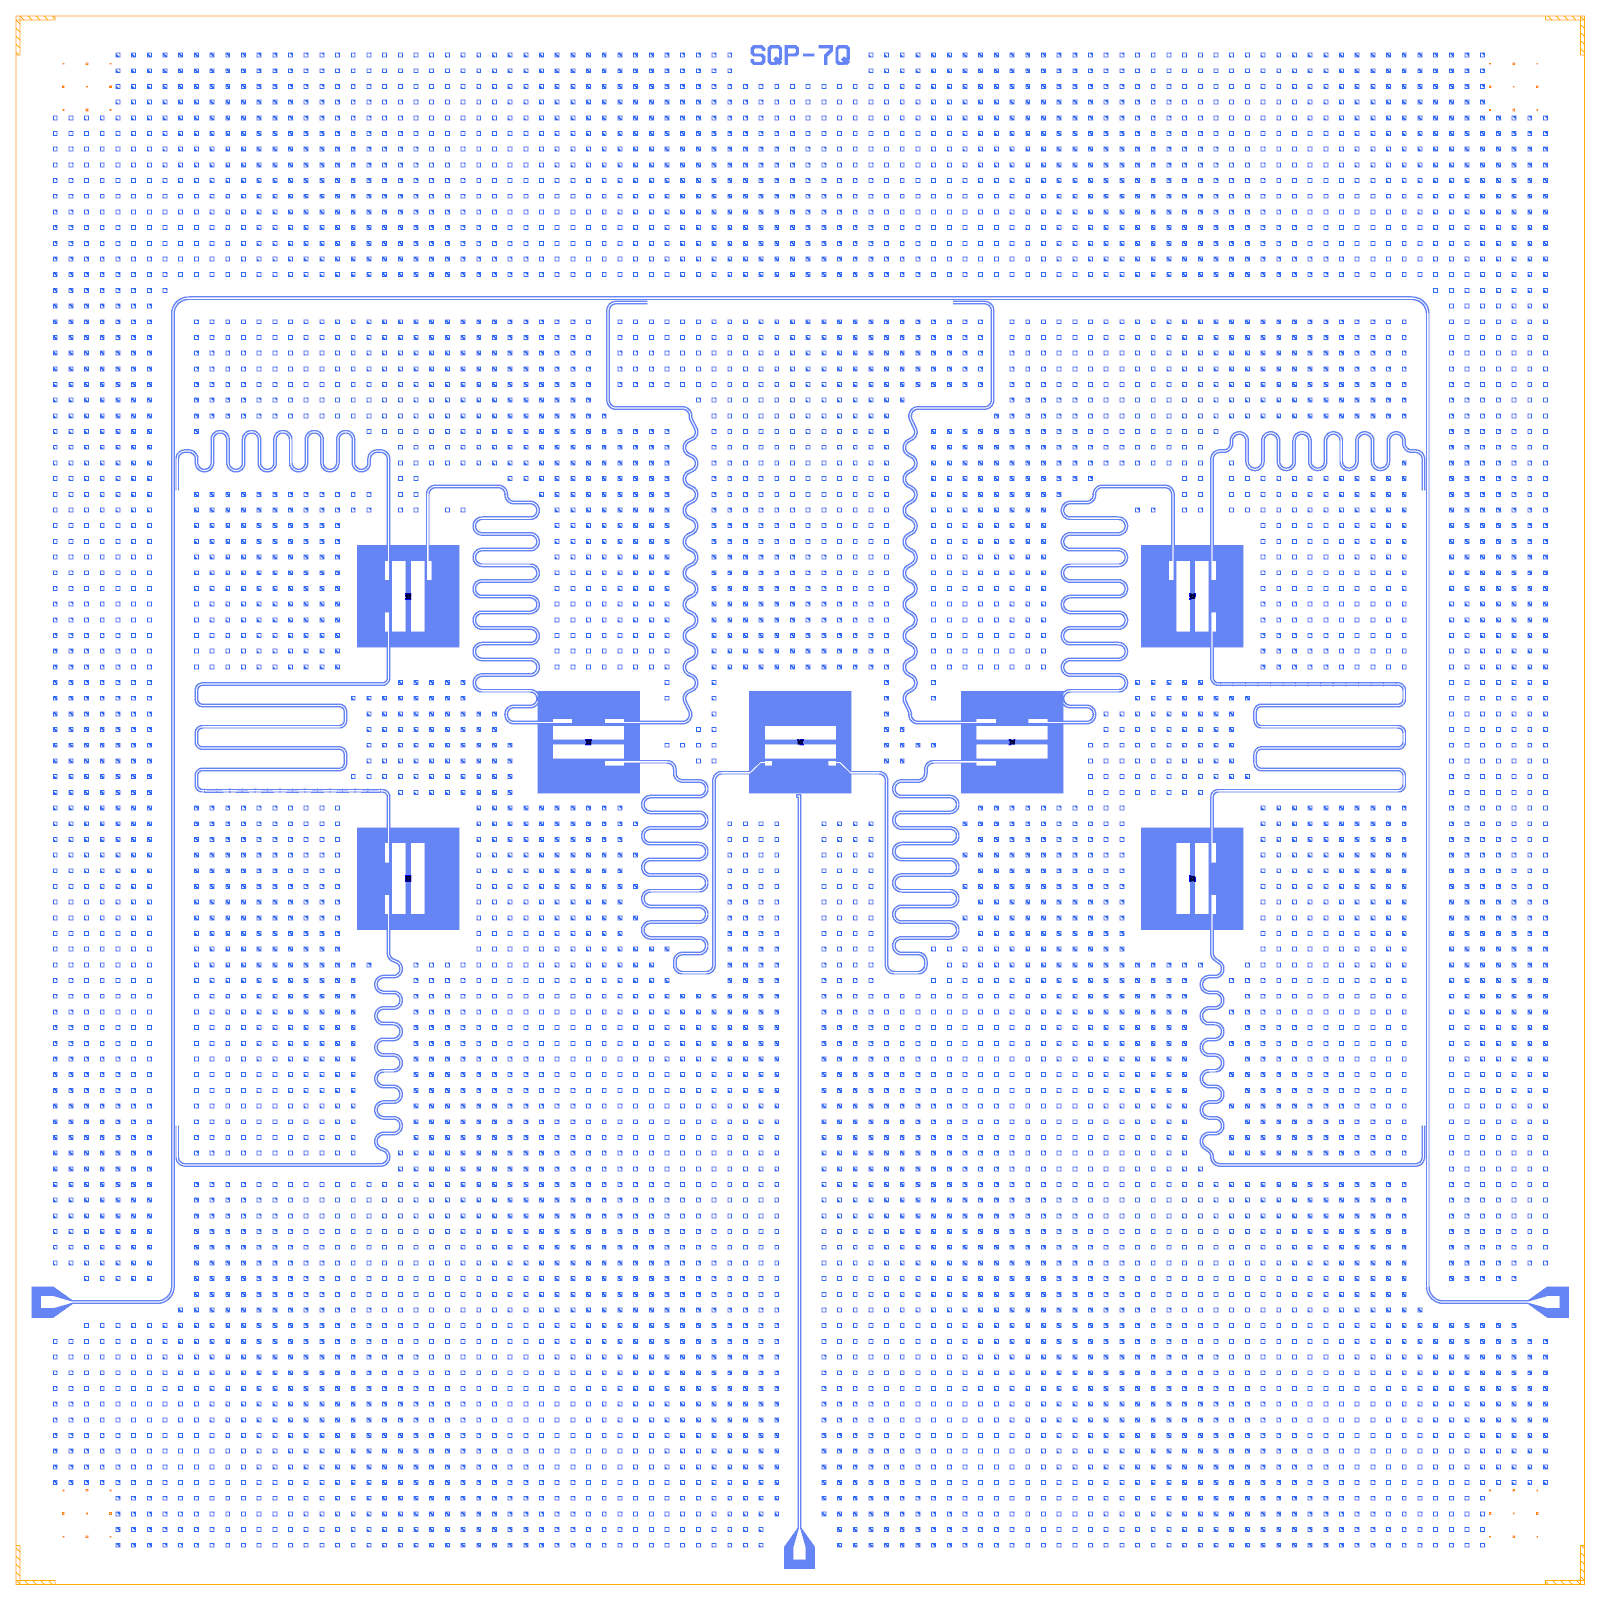

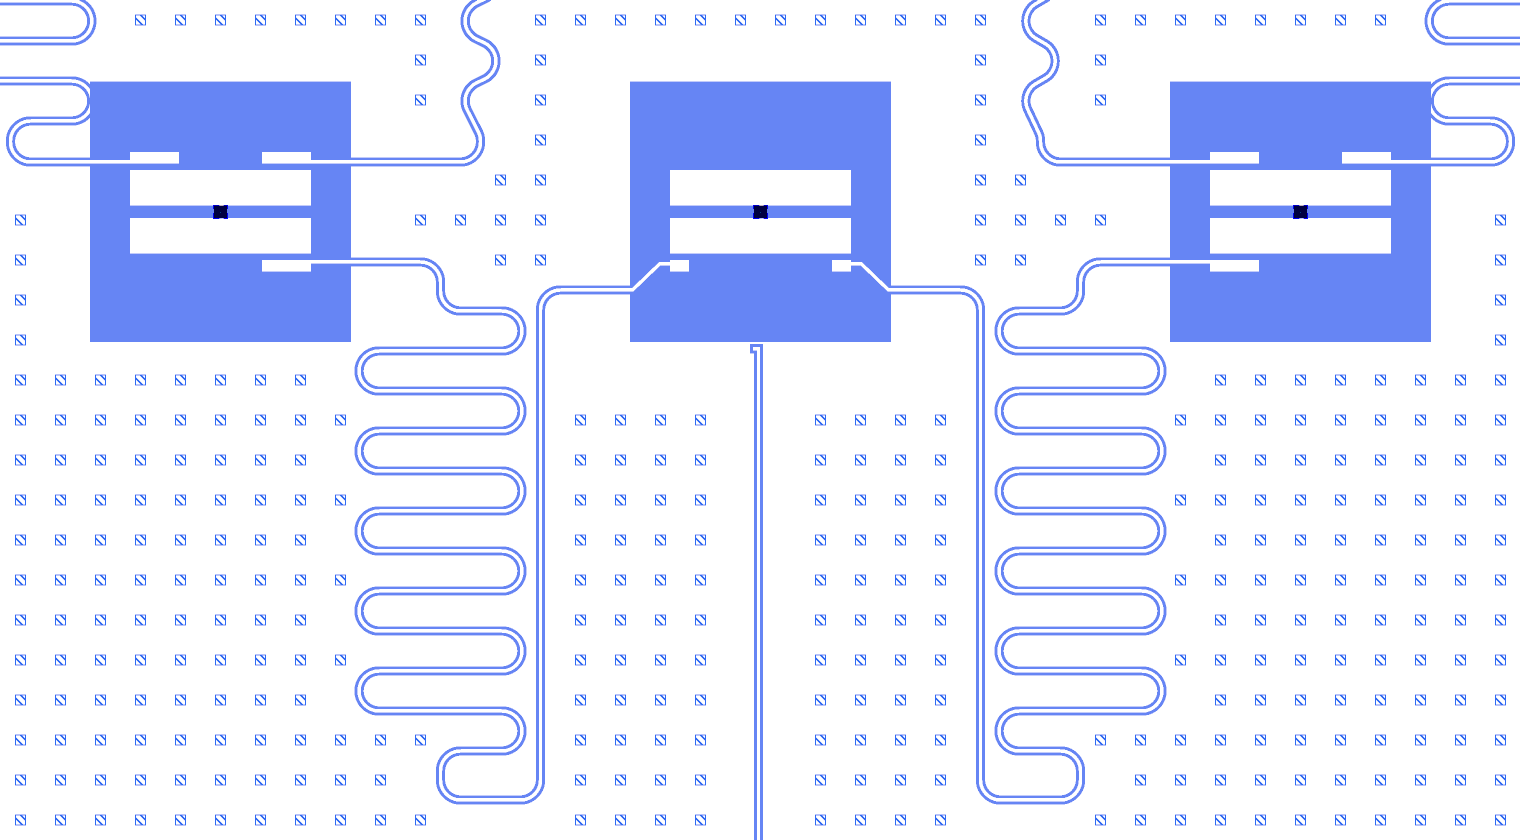

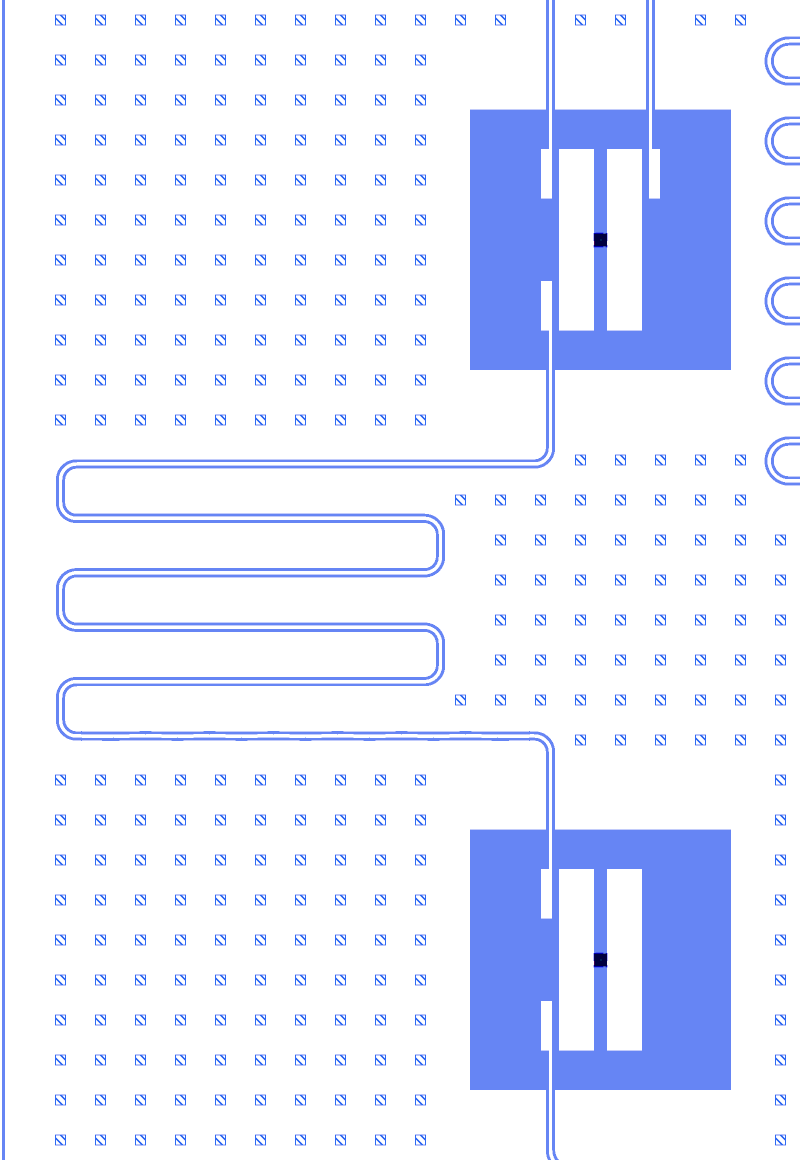

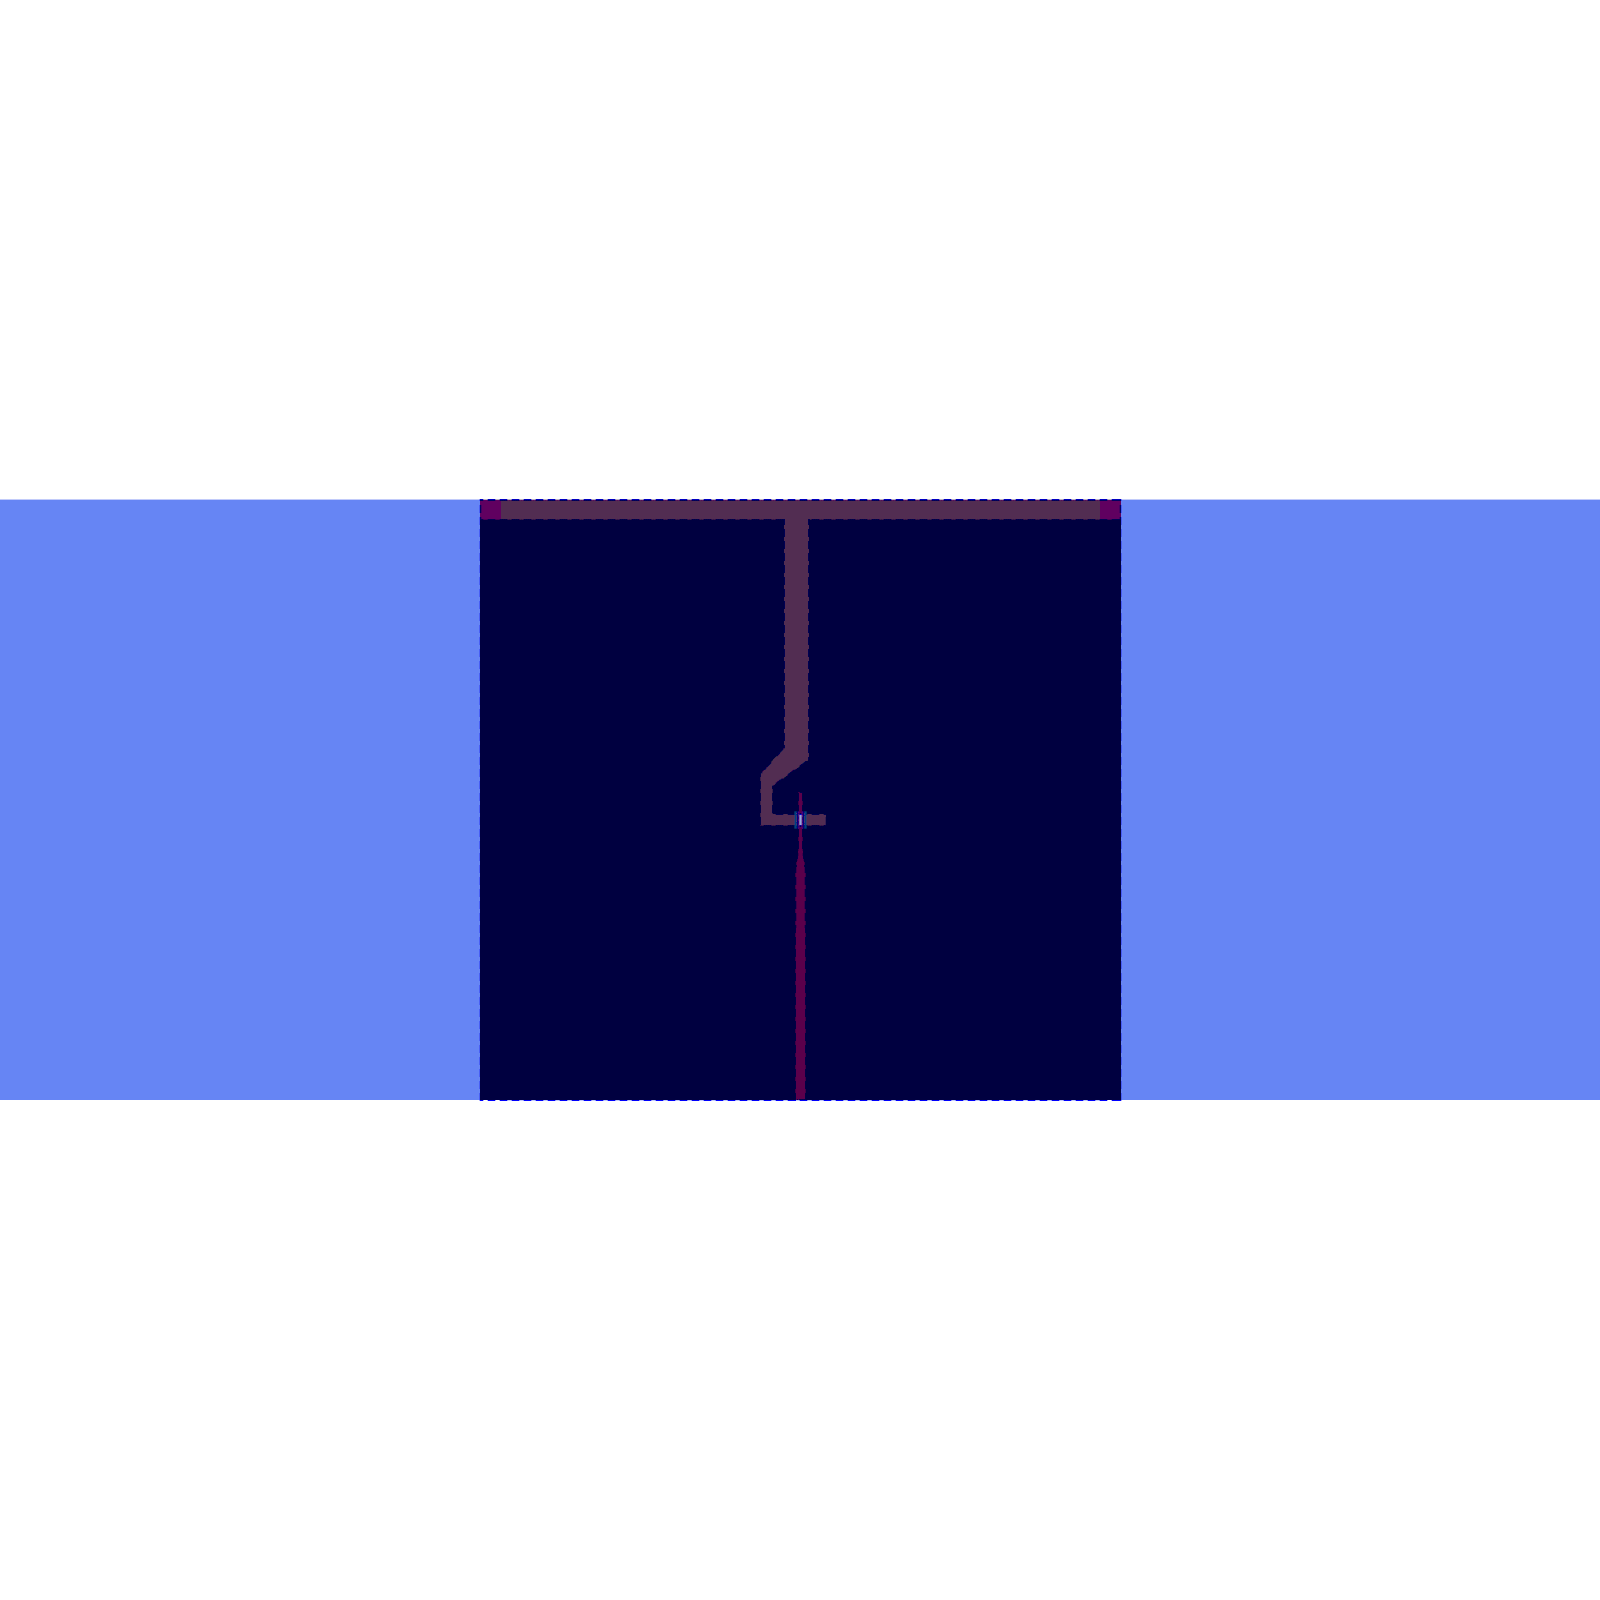

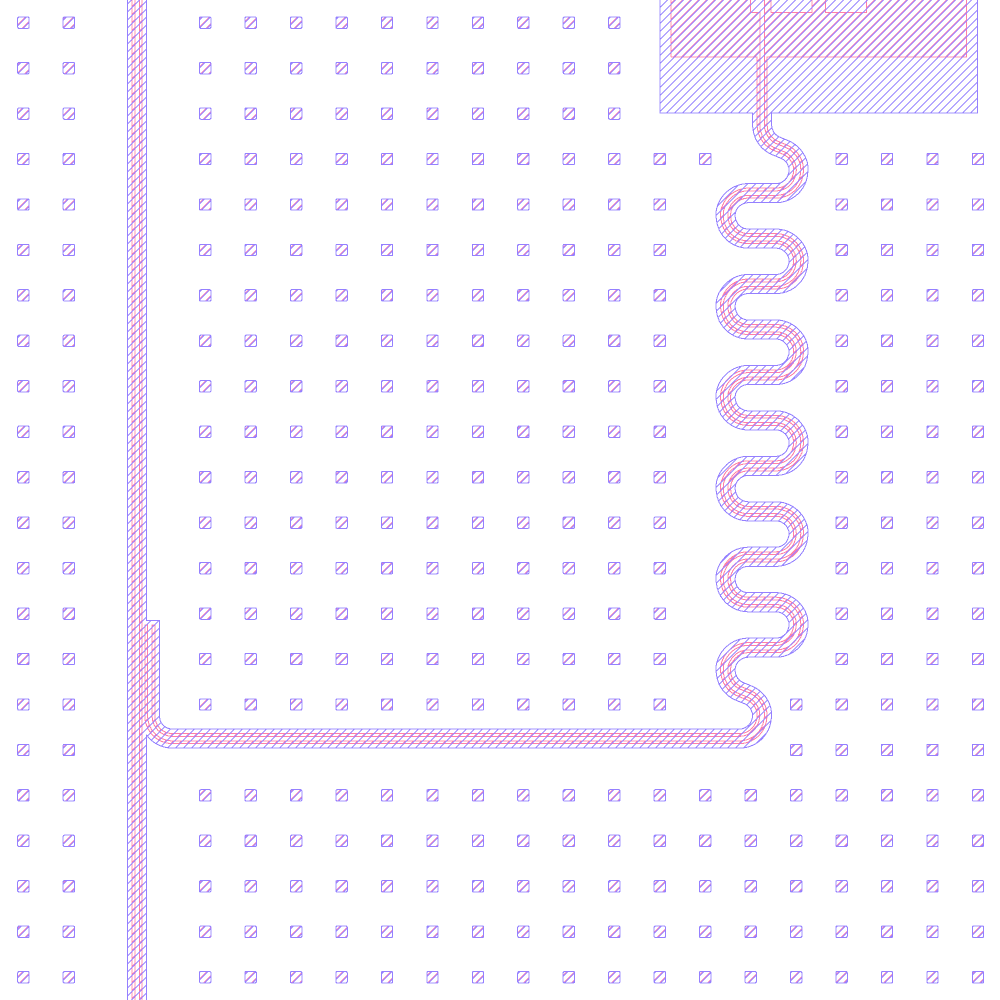

In [18]:
snap(d, OUT / "seven_qubit_processor.png", size=(1600, 1600))
dy = shift[1]
snap(d, OUT / "seven_qubit_processor_chain.png", box=(3100, 4300 + dy, 6900, 6400 + dy), size=(1520, 840), width=640)
snap(d, OUT / "seven_qubit_processor_q0q1.png", box=(1000, 4500 + dy, 3000, 7400 + dy), size=(800, 1160), width=320)
snap(d, OUT / "seven_qubit_processor_jj.png", box=(4960, 5830 + dy, 5040, 5910 + dy), width=300)
snap_file(FAB, OUT / "seven_qubit_processor_cheese.png", box=(700, 2600 + dy, 2900, 4800 + dy), size=(1000, 1000), width=400);

## 15 · Summary

- **Matches the source:** the qubit cells and options, positions and orientations, the U chain and its 7 mm buses, Q4's
  charge line, the original's Metal cheese (drawn by the build, kept in the mask: 7260 holes).
- **Changed or added:** λ/4 hangers on a ∩ feedline instead of galvanic readout meanders (the source has no
  resonators), three launchpads instead of six readout pads; the PDK frame, sapphire, trilayer junctions; the pads 100 µm
  from the die edge; the core centred in the die (shifted down 500 µm).
- **Open PDK design warnings:** `pdk_rn` on all seven junctions (86–102 kΩ for the 4.8–5.2 GHz plan; flagged, not
  retuned). f_q within 2.8 % of the plan, f_r within 0.9 %.
- **Known LOM limits:** α is above the README window (low pocket C_Σ in the LOM); the Q3D jobs replace the estimate (not solved:
  `RUN_FEM = False`).